# Phân tích và dự báo xu hướng giá nhà Phú Hòa – Thủ Dầu Một (phiên bản 2, dữ liệu thật)

**Mã sinh viên:** 2324801030095
**Họ và tên:** Nguyễn Quang Long
**Lớp:** D23KTPM01

**Thay đổi so với phiên bản 1.** Phiên bản 1 tạo **lịch sử giá mô phỏng** 2021–2026 theo giả định, rồi huấn luyện mô hình trên chính dữ liệu đó, nên kết quả chỉ phản ánh giả định. Phiên bản 2 **bỏ hoàn toàn dữ liệu mô phỏng** (bản cũ lưu ở `ban_cu/`). Mọi con số dưới đây tính từ tin rao thật hoặc trích từ báo cáo thị trường đã công bố (có ghi nguồn).

**Dữ liệu thật đang có và chưa có**

| Có | Chưa có (và lý do) |
|---|---|
| ~1.500 căn rao bán thật ở Bình Dương cũ, thu thập 12–14/11/2026 (notebook `2324801030095.ipynb`) | Lịch sử giá nhiều năm của từng phường: các trang rao vặt chỉ hiển thị tin đang đăng; kho lưu trữ web (Internet Archive) từ chối truy cập tự động từ máy này |
| **Giá gốc lúc đăng** và giá hiện tại của từng tin Chợ Tốt → biết người bán đã tăng hay giảm giá | Giá giao dịch công chứng: không công khai |
| Ngày đăng của từng tin (tháng 9–11/2026) | |
| Số liệu thị trường DKRA Consulting (TP.HCM & vùng phụ cận) đã công bố, có đối chiếu nguyên văn | Số liệu chính thức riêng cho Thủ Dầu Một / Phú Hòa |

**Hệ quả về phương pháp:** với chuỗi thời gian quá ngắn, **không thể huấn luyện và kiểm chứng trung thực** một mô hình học máy dự báo giá 6–12 tháng (không có đủ kỳ quá khứ để kiểm định lùi). Vì vậy notebook:
1. Đo **mặt bằng giá hiện tại** bằng mô hình định giá (Bước 1);
2. Đo **xu hướng ngắn hạn** từ các tín hiệu thật trong dữ liệu (Bước 2–4) và đối chiếu với báo cáo thị trường (Bước 5);
3. Đưa ra **nhận định 6–12 tháng có điều kiện**, ghi rõ cách tính từng con số (Bước 6);
4. Xây sẵn **bộ chỉ số theo ảnh chụp định kỳ** (Bước 7): mỗi lần chạy `thu_thap/cap_nhat_dinh_ky.py` thêm một kỳ dữ liệu thật. Khi đủ kỳ, mô hình dự báo được huấn luyện và **kiểm định lùi** tự động.

In [1]:
import glob, json, re, warnings
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from mo_hinh_gia import khong_dau, trich_dac_trung_chu

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 200)
DATA_DIR, MODEL_DIR = Path("data"), Path("model")
rng = np.random.default_rng(42)

df = pd.read_csv(DATA_DIR / "nha_da_xu_ly.csv")
goi = joblib.load(MODEL_DIR / "mo_hinh_gia_nha.joblib")
mo_hinh, Q = goi["model"], goi["phan_vi_sai_so"]
raw_ct = pd.read_csv(DATA_DIR / "chotot_binh_duong_raw.csv")
TEN_PHUONG = {re.sub(r"^(phuong|xa|thi tran)\s*", "", khong_dau(p)).strip(): re.sub(r"^Phường\s*", "", p)
              for p in raw_ct["phuong"].dropna().unique()}
TEN_PHUONG["phu hoa"] = "Phú Hòa"
print(f"Dữ liệu sạch: {len(df)} căn, mô hình định giá: {goi['ten']} (dữ liệu ngày {goi['ngay_du_lieu']})")

Dữ liệu sạch: 1476 căn, mô hình định giá: Ensemble + chữ (dữ liệu ngày 2026-11-14)


## Bước 1: Mặt bằng giá hiện tại – định giá "căn nhà chuẩn" ở từng phường
So đơn giá trung vị thô giữa các phường dễ sai vì mỗi phường rao những loại nhà khác nhau (phường này nhiều nhà mặt tiền lớn, phường kia nhiều nhà hẻm nhỏ). Cách làm chuẩn trong định giá (hedonic): **giữ nguyên một căn nhà mẫu** rồi dùng mô hình định giá nó ở từng vị trí.

**Căn chuẩn:** đất 100 m² (5 × 20 m), 1 trệt 1 lầu (sàn 180 m²), 3 phòng ngủ, 2 WC, hẻm xe hơi rộng 5 m, sổ riêng. Vị trí lấy bằng tọa độ trung vị các tin của phường đó.

,Phường (cũ),Số tin,Giá căn chuẩn (tỷ),Khoảng 80% (tỷ),Đơn giá căn chuẩn (tr/m²),Đơn giá rao trung vị (tr/m²)
1,Phú Cường,8,3.80,2.70 – 5.30,37.98,52.04
2,Hiệp Thành,41,3.61,2.56 – 5.03,36.05,51.67
3,Chánh Nghĩa,30,3.27,2.32 – 4.56,32.68,38.13
4,Phú Hòa,219,3.25,2.31 – 4.53,32.47,38.19
5,Phú Lợi,44,3.22,2.29 – 4.50,32.21,41.53
6,Phú Mỹ,55,3.18,2.26 – 4.44,31.84,42.22
7,Hoà Phú,30,3.11,2.21 – 4.34,31.08,42.91
8,Phú Thọ,16,3.09,2.20 – 4.32,30.95,43.48
9,Hiệp An,21,2.83,2.01 – 3.95,28.28,29.11
10,Định Hoà,23,2.64,1.87 – 3.68,26.36,31.90


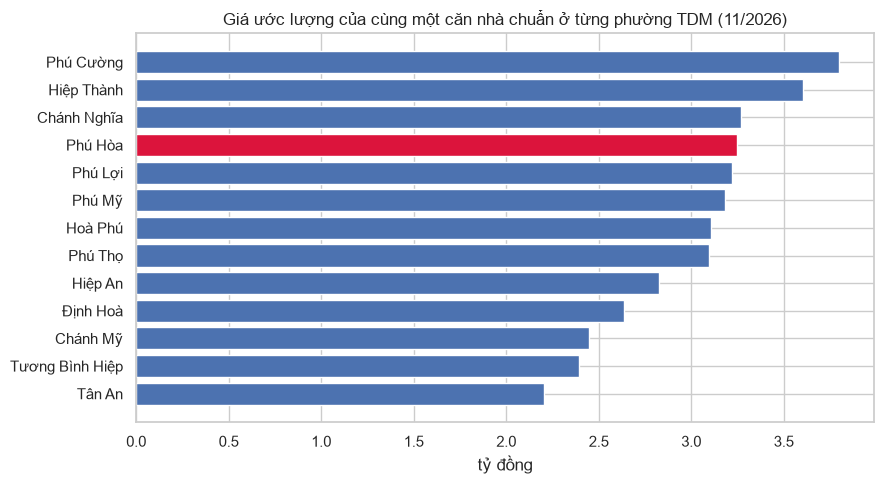

In [2]:
def tao_can(lat, lon, phuong, quan="thu dau mot", duong=None, cap_loi_vao=2, hem_rong=5.0, mat_tien=0,
            dt_dat=100, ngang=5, dai=20, so_tang=2, dt_san=180, phong_ngu=3, so_wc=2, mo_ta="hẻm xe hơi sổ riêng"):
    can = pd.DataFrame([{"dt_dat": dt_dat, "ngang": ngang, "dai": dai, "so_tang": so_tang, "dt_san": dt_san, "phong_ngu": phong_ngu,
                         "so_wc": so_wc, "mat_tien_duong": mat_tien, "cap_loi_vao": cap_loi_vao, "hem_rong": hem_rong,
                         "so_chung": 0.0, "noi_that": np.nan, "quan": quan, "phuong": phuong, "duong": duong,
                         "lat": lat, "lon": lon, "van_ban": khong_dau(mo_ta)}])
    can = pd.concat([can, trich_dac_trung_chu(can["van_ban"])], axis=1)
    can["log_dt"] = np.log(can["dt_dat"]); can["ty_le_san"] = can["dt_san"] / can["dt_dat"]
    can["kc_trung_tam_km"] = np.hypot((lat - 10.9805) * 110.6, (lon - 106.6520) * 109.3)
    return can

def dinh_gia(can):
    p = float(mo_hinh.predict(can)[0])
    return np.exp(p), np.exp(p + Q["q10"]), np.exp(p + Q["q90"])

tdm = df[df["quan"] == "thu dau mot"]
rows = []
for ph_, g in tdm.groupby("phuong"):
    if len(g) < 8:
        continue
    gia, lo, hi = dinh_gia(tao_can(g["lat"].median(), g["lon"].median(), ph_))
    rows.append({"Phường (cũ)": TEN_PHUONG.get(ph_, ph_), "Số tin": len(g), "Giá căn chuẩn (tỷ)": gia,
                 "Khoảng 80% (tỷ)": f"{lo:.2f} – {hi:.2f}", "Đơn giá căn chuẩn (tr/m²)": gia * 10,
                 "Đơn giá rao trung vị (tr/m²)": g["don_gia"].median()})
CHUAN = pd.DataFrame(rows).sort_values("Giá căn chuẩn (tỷ)", ascending=False).reset_index(drop=True)
CHUAN.index += 1
display(CHUAN.round(2))

fig, ax = plt.subplots(figsize=(9, 5))
mau = ["crimson" if p == "Phú Hòa" else "#4C72B0" for p in CHUAN["Phường (cũ)"]]
ax.barh(CHUAN["Phường (cũ)"], CHUAN["Giá căn chuẩn (tỷ)"], color=mau); ax.invert_yaxis()
ax.set(title="Giá ước lượng của cùng một căn nhà chuẩn ở từng phường TDM (11/2026)", xlabel="tỷ đồng")
plt.tight_layout(); plt.show()

**Đọc kết quả:** bảng cho biết **vị thế giá** của Phú Hòa so với các phường khác khi so trên cùng một căn nhà. Cột đơn giá rao trung vị (thô) khác cột đơn giá căn chuẩn vì mỗi phường rao loại nhà khác nhau. Đây là lý do cần định giá chuẩn hóa.

Trong Phú Hòa, vị trí và lối vào tạo chênh lệch lớn. Định giá cùng căn chuẩn khi nằm trong hẻm xe hơi và khi nằm ở mặt tiền các trục chính:

In [3]:
ph = df[df["phuong"] == "phu hoa"]
rows = []
lat0, lon0 = ph["lat"].median(), ph["lon"].median()
for ten, kw in [("Hẻm nhỏ 2,5 m", dict(cap_loi_vao=0.5, hem_rong=2.5, mo_ta="hẻm nhỏ sổ riêng")),
                ("Hẻm xe hơi 5 m", dict(cap_loi_vao=2, hem_rong=5)),
                ("Hẻm xe tải 7 m, khu dân cư", dict(cap_loi_vao=4, hem_rong=7, mo_ta="khu dân cư hẻm xe hơi sổ riêng"))]:
    rows.append((ten, *dinh_gia(tao_can(lat0, lon0, "phu hoa", **kw))))
TEN_DUONG = {"nguyen thi minh khai": "Nguyễn Thị Minh Khai", "le hong phong": "Lê Hồng Phong", "nguyen thai binh": "Nguyễn Thái Bình", "phu loi": "Phú Lợi"}
for duong in TEN_DUONG:
    g = df[(df["quan"] == "thu dau mot") & (df["duong"] == duong)]
    if len(g) >= 3:
        rows.append((f"Mặt tiền đường {TEN_DUONG[duong]}", *dinh_gia(tao_can(g["lat"].median(), g["lon"].median(), "phu hoa", duong=duong,
                                                                     cap_loi_vao=5, hem_rong=20, mat_tien=1, mo_ta="mặt tiền kinh doanh sổ riêng"))))
VT = pd.DataFrame(rows, columns=["Vị trí trong Phú Hòa", "Giá (tỷ)", "Thấp 80%", "Cao 80%"]).set_index("Vị trí trong Phú Hòa")
VT["So với hẻm xe hơi (%)"] = (VT["Giá (tỷ)"] / VT.loc["Hẻm xe hơi 5 m", "Giá (tỷ)"] - 1) * 100
VT.round(2)

,Giá (tỷ),Thấp 80%,Cao 80%,So với hẻm xe hơi (%)
Vị trí trong Phú Hòa,,,,
"Hẻm nhỏ 2,5 m",3.07,2.18,4.29,-5.44
Hẻm xe hơi 5 m,3.25,2.31,4.53,0.00
"Hẻm xe tải 7 m, khu dân cư",3.32,2.36,4.64,2.37
Mặt tiền đường Nguyễn Thị Minh Khai,5.41,3.85,7.56,66.70
Mặt tiền đường Lê Hồng Phong,5.80,4.12,8.10,78.69
Mặt tiền đường Nguyễn Thái Bình,5.83,4.14,8.14,79.52
Mặt tiền đường Phú Lợi,6.23,4.43,8.70,91.95


## Bước 2: Tín hiệu 1 – Người bán đang tăng hay giảm giá? (cùng một căn)
Chợ Tốt lưu **giá lúc đăng tin lần đầu** (`gia_goc_luc_dang`) và **giá hiện tại**. Với cùng một căn, mọi khác biệt về diện tích, vị trí, chất lượng đều triệt tiêu, nên đây là thước đo **trực tiếp, sạch nhất** về biến động giá rao trong dữ liệu (cách làm tương tự chỉ số giá lặp lại – *repeat-sales*).

Loại các thay đổi > ±40%: đó là sửa lỗi đơn vị (ví dụ 2.500.000 → 2.500.000.000), không phải đổi giá.

,Số tin bán,Số tin đã đổi giá,% tin đổi giá,Trong số đổi giá: % GIẢM,KTC 95% của % giảm,Mức đổi trung vị (%),KTC 95% mức đổi,Thay đổi bình quân trên MỌI tin (%)
Toàn Bình Dương cũ,1562,199,12.740077,78.39196,72–84%,-4.558824,-5.5% … -3.7%,-0.606654
Phú Hòa,63,6,9.52381,100.0,100–100%,-10.275229,-16.8% … -5.2%,-1.092007
TDM (phường khác),374,28,7.486631,64.285714,46–82%,-2.812981,-4.7% … +1.9%,-0.144913
Bình Dương cũ (ngoài TDM),1125,165,14.666667,80.0,74–86%,-4.97479,-5.6% … -3.7%,-0.732476
Toàn TDM,437,34,7.78032,70.588235,56–85%,-3.421092,-5.9% … -1.6%,-0.282008


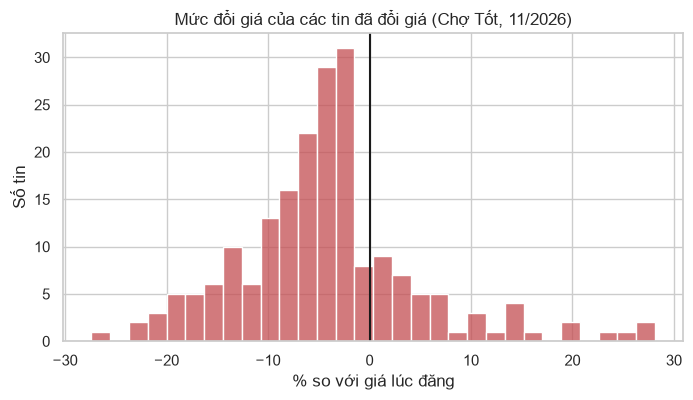

In [4]:
ct = raw_ct[(raw_ct["loai_tin"] == "ban") & raw_ct["gia_goc_luc_dang"].notna() & (raw_ct["gia"] > 0)].copy()
ct["r"] = np.log(ct["gia"] / ct["gia_goc_luc_dang"])
ct["khu_vuc"] = np.where(ct["phuong"] == "Phường Phú Hòa", "Phú Hòa",
                 np.where(ct["quan_huyen"].str.contains("Thủ Dầu Một"), "TDM (phường khác)", "Bình Dương cũ (ngoài TDM)"))
doi = ct[(ct["r"] != 0) & (ct["r"].abs() < np.log(1.4))]

def bootstrap(x, f, n=4000):
    x = np.asarray(x); b = [f(rng.choice(x, len(x))) for _ in range(n)]
    return np.percentile(b, [2.5, 97.5])

def tom_tat(g_all, g_doi):
    lo, hi = bootstrap(g_doi["r"], lambda v: np.mean(v < 0)) if len(g_doi) else (np.nan, np.nan)
    mlo, mhi = bootstrap(g_doi["r"], np.median) if len(g_doi) else (np.nan, np.nan)
    return pd.Series({"Số tin bán": len(g_all), "Số tin đã đổi giá": len(g_doi),
                      "% tin đổi giá": len(g_doi) / len(g_all) * 100,
                      "Trong số đổi giá: % GIẢM": np.mean(g_doi["r"] < 0) * 100,
                      "KTC 95% của % giảm": f"{lo*100:.0f}–{hi*100:.0f}%",
                      "Mức đổi trung vị (%)": (np.exp(np.median(g_doi["r"])) - 1) * 100,
                      "KTC 95% mức đổi": f"{(np.exp(mlo)-1)*100:+.1f}% … {(np.exp(mhi)-1)*100:+.1f}%",
                      "Thay đổi bình quân trên MỌI tin (%)": (np.exp(ct.loc[g_all.index, "r"].where(lambda s: s.abs() < np.log(1.4), 0).mean()) - 1) * 100})

BANG_DOI = pd.DataFrame({"Toàn Bình Dương cũ": tom_tat(ct, doi)})
for kv in ["Phú Hòa", "TDM (phường khác)", "Bình Dương cũ (ngoài TDM)"]:
    BANG_DOI[kv] = tom_tat(ct[ct["khu_vuc"] == kv], doi[doi["khu_vuc"] == kv])
tdm_all = ct[ct["khu_vuc"] != "Bình Dương cũ (ngoài TDM)"]
BANG_DOI["Toàn TDM"] = tom_tat(tdm_all, doi[doi["khu_vuc"] != "Bình Dương cũ (ngoài TDM)"])
display(BANG_DOI.T)

fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot((np.exp(doi["r"]) - 1) * 100, bins=30, ax=ax, color="#C44E52")
ax.axvline(0, color="k"); ax.set(title="Mức đổi giá của các tin đã đổi giá (Chợ Tốt, 11/2026)", xlabel="% so với giá lúc đăng", ylabel="Số tin")
plt.show()

**Đọc kết quả:** trong các tin đã đổi giá, **phần lớn là giảm giá**, và khoảng tin cậy 95% của tỷ lệ này nằm hẳn trên 50%. Như vậy người bán đang **hạ kỳ vọng** chứ không nâng giá. Mức giảm điển hình vài phần trăm. Tính bình quân trên mọi tin (kể cả tin giữ nguyên giá), mặt bằng giá rao chỉ dịch chuyển nhẹ.

Các ô "Phú Hòa" có rất ít tin nên chỉ để tham khảo; con số của toàn TDM và toàn vùng đáng tin hơn.

## Bước 3: Tín hiệu 2 – Giá rao theo tuần đăng tin
Mỗi căn có **giá rao** và **giá ước lượng** (do mô hình định giá tính ngoài-fold, không học căn đó). Tỷ số log(giá rao / giá ước lượng) đã loại ảnh hưởng của diện tích, vị trí, loại nhà. Nếu các tin đăng gần đây có tỷ số thấp hơn tin đăng trước, mặt bằng giá rao đang đi xuống.

⚠️ **Thiên lệch cần biết:** tin đăng lâu mà vẫn còn hiển thị thường là tin **rao quá cao nên chưa bán được**. Hiện tượng này tự tạo ra một đường "giảm" giả, nên tín hiệu này yếu hơn Bước 2 và chỉ dùng để đối chiếu.

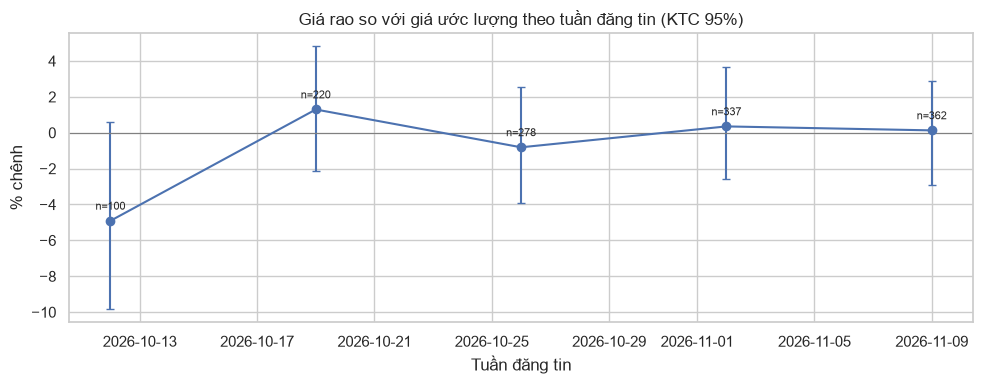

Độ dốc: -0.37 điểm %/tháng (KTC 95%: -4.75 … +4.15); số tin: 1330; giai đoạn: 2026-08-16 → 2026-11-14


In [5]:
d3 = df[df["nguon"].isin(["chotot", "alonhadat"]) & df["ngay_dang"].notna()].copy()
d3["ngay_dang"] = pd.to_datetime(d3["ngay_dang"])
d3["lech"] = np.log(d3["gia_ty"] / d3["gia_uoc_luong_ty"])
d3["tuan"] = d3["ngay_dang"].dt.to_period("W").dt.start_time
tuan = d3.groupby("tuan")["lech"].agg(["size", "mean"]).query("size >= 15")
ci = np.array([bootstrap(d3.loc[d3["tuan"] == t, "lech"], np.mean, 1000) for t in tuan.index])
ngay_so = (d3["ngay_dang"] - d3["ngay_dang"].min()).dt.days.to_numpy()
def doc(idx):
    return np.polyfit(ngay_so[idx], d3["lech"].to_numpy()[idx], 1)[0] * 30 * 100
slope = doc(np.arange(len(d3)))
slo, shi = np.percentile([doc(rng.integers(0, len(d3), len(d3))) for _ in range(2000)], [2.5, 97.5])

fig, ax = plt.subplots(figsize=(10, 4))
ax.errorbar(tuan.index, (np.exp(tuan["mean"]) - 1) * 100, yerr=[(np.exp(tuan["mean"]) - np.exp(ci[:, 0])) * 100, (np.exp(ci[:, 1]) - np.exp(tuan["mean"])) * 100],
            fmt="o-", capsize=3)
for t, n in tuan["size"].items():
    ax.annotate(f"n={n}", (t, (np.exp(tuan.loc[t, "mean"]) - 1) * 100), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8)
ax.axhline(0, color="gray", lw=0.8)
ax.set(title="Giá rao so với giá ước lượng theo tuần đăng tin (KTC 95%)", ylabel="% chênh", xlabel="Tuần đăng tin")
plt.tight_layout(); plt.show()
print(f"Độ dốc: {slope:+.2f} điểm %/tháng (KTC 95%: {slo:+.2f} … {shi:+.2f}); số tin: {len(d3)}; "
      f"giai đoạn: {d3['ngay_dang'].min().date()} → {d3['ngay_dang'].max().date()}")

**Đọc kết quả:** đọc độ dốc cùng khoảng tin cậy. Nếu khoảng tin cậy chứa 0 thì dữ liệu ~2 tháng **chưa đủ** để khẳng định giá rao tăng hay giảm theo thời gian. Nếu âm rõ, cần nhớ một phần đến từ thiên lệch "tin cũ là tin rao cao" ở trên.

## Bước 4: Tín hiệu 3 – Áp lực bán
- Tỷ lệ tin có từ khóa **"bán gấp / ngộp / cắt lỗ / giảm giá / kẹt tiền"**;
- Tỷ lệ tin được mô hình chẩn đoán **"rẻ hơn thị trường"** và **"cao hơn thị trường"** (từ notebook chính).

In [6]:
df["khu_vuc"] = np.where(df["phuong"] == "phu hoa", "Phú Hòa", np.where(df["quan"] == "thu dau mot", "TDM (phường khác)", "Ngoài TDM"))
AP_LUC = df.groupby("khu_vuc").agg(so_can=("y", "size"), ban_gap_pt=("t_ban_gap", "mean"),
                                    re_hon_pt=("chan_doan", lambda s: (s == "Rẻ hơn thị trường").mean()),
                                    cao_hon_pt=("chan_doan", lambda s: (s == "Cao hơn thị trường").mean()),
                                    lech_tv_pt=("chenh_lech_pt", "median"))
AP_LUC[["ban_gap_pt", "re_hon_pt", "cao_hon_pt"]] *= 100
AP_LUC.columns = ["Số căn", "% tin 'bán gấp/giảm giá'", "% rẻ hơn thị trường", "% cao hơn thị trường", "Giá rao lệch trung vị so với ước lượng (%)"]
AP_LUC.round(1)

,Số căn,% tin 'bán gấp/giảm giá',% rẻ hơn thị trường,% cao hơn thị trường,Giá rao lệch trung vị so với ước lượng (%)
khu_vuc,,,,,
Ngoài TDM,860,19.8,9.9,8.6,-0.9
Phú Hòa,219,5.5,9.6,16.4,-0.2
TDM (phường khác),397,15.4,11.6,11.8,2.8


**Đọc kết quả:** khoảng 12–20% số tin (tùy khu vực) có lời lẽ "bán gấp / giảm giá". Tỷ lệ ở Phú Hòa thấp hơn một phần vì tin guland chỉ có tiêu đề, không có mô tả. Đây là dấu hiệu thị trường **thuận lợi cho người mua**, phù hợp với tín hiệu giảm giá ở Bước 2. Tỷ lệ căn "rẻ hơn" và "cao hơn thị trường" xấp xỉ nhau, nên mặt bằng giá rao **chưa lệch hẳn về một phía** so với giá trị ước lượng.

## Bước 5: Bối cảnh thị trường đã công bố
Các số liệu dưới đây đã được đối chiếu với **nguyên văn** bài báo. Chúng là số liệu của **TP.HCM và vùng phụ cận** (gồm Bình Dương cũ), không riêng Thủ Dầu Một, và các mốc so sánh khác nhau (so cùng kỳ / quý trước / tháng trước). Vì vậy **không ghép thành một chuỗi số**, chỉ dùng để xác định chiều của thị trường.

In [7]:
BOI_CANH = pd.DataFrame([
    ["2025 (tổng kết năm)", "Nhà phố, biệt thự – thứ cấp", "+12 – 19% so với đầu năm", "Tiếp Thị Gia Đình, 12/01/2026 (số liệu năm 2025 không ghi rõ đơn vị; phần dự báo ghi DKRA)",
     "https://tiepthigiadinh.vn/du-bao-thi-truong-bat-dong-san-nam-2026-d30043.html"],
    ["2 tháng đầu 2026", "Nhà phố, biệt thự – thứ cấp", "Đi ngang so với Q4/2025; +13 – 17% so với cùng kỳ 2025", "DKRA Consulting, qua Nhịp sống kinh doanh 17/03/2026",
     "https://nhipsongkinhdoanh.vn/bat-dong-san-phia-nam-2-thang-dau-nam-2026--bat-ngo-mot-phan-khuc-giao-dich-tang-31-lan-26667.htm"],
    ["Quý II/2026", "Nhà phố, biệt thự – thứ cấp", "+2% so với quý trước, cục bộ ở dự án hoàn thiện pháp lý", "DKRA Consulting, qua Việt Báo 11/07/2026",
     "https://vietbao.vn/can-ho-dat-nen-nha-pho-biet-thu-tp-ho-chi-minh-co-chuyen-dong-moi-598552.html"],
    ["Tháng 10/2026", "Nhà phố, biệt thự – thứ cấp", "−8% so với tháng trước; tiêu thụ chỉ ~5% nguồn cung; sơ cấp đi ngang", "DKRA Consulting, qua CafeF 13/11/2026",
     "https://cafef.vn/tphcm-cu-100-can-biet-thu-nha-pho-duoc-ban-ra-thi-co-toi-95-can-khong-ban-duoc-188261113135928595.chn"],
], columns=["Thời điểm", "Phân khúc", "Biến động giá", "Nguồn", "Link"])
BOI_CANH

,Thời điểm,Phân khúc,Biến động giá,Nguồn,Link
0,2025 (tổng kết năm),"Nhà phố, biệt thự – thứ cấp",+12 – 19% so với đầu năm,"Tiếp Thị Gia Đình, 12/01/2026 (số liệu năm 202...",https://tiepthigiadinh.vn/du-bao-thi-truong-ba...
1,2 tháng đầu 2026,"Nhà phố, biệt thự – thứ cấp",Đi ngang so với Q4/2025; +13 – 17% so với cùng...,"DKRA Consulting, qua Nhịp sống kinh doanh 17/0...",https://nhipsongkinhdoanh.vn/bat-dong-san-phia...
2,Quý II/2026,"Nhà phố, biệt thự – thứ cấp","+2% so với quý trước, cục bộ ở dự án hoàn thiệ...","DKRA Consulting, qua Việt Báo 11/07/2026",https://vietbao.vn/can-ho-dat-nen-nha-pho-biet...
3,Tháng 10/2026,"Nhà phố, biệt thự – thứ cấp",−8% so với tháng trước; tiêu thụ chỉ ~5% nguồn...,"DKRA Consulting, qua CafeF 13/11/2026",https://cafef.vn/tphcm-cu-100-can-biet-thu-nha...


**Đọc kết quả:** giá nhà phố thứ cấp khu vực tăng mạnh trong 2025 và đầu 2026, chậm lại ở quý II/2026, rồi **đảo chiều giảm** ở tháng 10/2026 khi thanh khoản rất thấp. Diễn biến này **cùng chiều** với tín hiệu từ dữ liệu của đề tài (Bước 2, 4): người bán ở Thủ Dầu Một đang giảm giá nhiều hơn tăng giá.

## Bước 6: Nhận định xu hướng 6–12 tháng tới
Tổng hợp các tín hiệu (chỉ dùng số đo được ở trên):

In [8]:
tdm_row = BANG_DOI["Toàn TDM"]
ph_row = BANG_DOI["Phú Hòa"]
TIN_HIEU = pd.DataFrame([
    ["Đổi giá cùng một căn (TDM)", f"{tdm_row['Trong số đổi giá: % GIẢM']:.0f}% số lần đổi giá là GIẢM; mức đổi trung vị {tdm_row['Mức đổi trung vị (%)']:+.1f}%",
     "Giảm", "Cao – đo trực tiếp trên cùng căn"],
    ["Đổi giá cùng một căn (toàn vùng)", f"{BANG_DOI['Toàn Bình Dương cũ']['Trong số đổi giá: % GIẢM']:.0f}% là GIẢM; trung vị {BANG_DOI['Toàn Bình Dương cũ']['Mức đổi trung vị (%)']:+.1f}%",
     "Giảm", "Cao"],
    ["Giá rao theo tuần đăng", f"{slope:+.2f} điểm %/tháng (KTC 95% {slo:+.2f} … {shi:+.2f})",
     "Giảm" if shi < 0 else ("Tăng" if slo > 0 else "Chưa rõ"), "Thấp – có thiên lệch tin tồn"],
    ["Tin 'bán gấp/giảm giá' (TDM)", f"{df[df['quan'] == 'thu dau mot']['t_ban_gap'].mean() * 100:.0f}% số tin", "Giảm", "Trung bình"],
    ["DKRA – nhà phố thứ cấp T10/2026", "−8% so với tháng trước, tiêu thụ ~5% nguồn cung", "Giảm", "Trung bình – số liệu vùng"],
    ["DKRA – nhà phố thứ cấp 12 tháng trước đó", "+13–17% so với cùng kỳ (đầu 2026)", "Tăng (đã qua)", "Trung bình – số liệu vùng"],
], columns=["Tín hiệu", "Giá trị đo được", "Chiều", "Độ tin cậy"])
display(TIN_HIEU)

# Biên của kịch bản: lấy trực tiếp từ các con số đo được, không tự đặt
giam_6t = min(tdm_row["Mức đổi trung vị (%)"], BANG_DOI["Toàn Bình Dương cũ"]["Mức đổi trung vị (%)"])   # mức người bán đang giảm
tang_6t = 2.0                                                    # DKRA Q2/2026: +2%/quý – mức tăng gần nhất trước khi đảo chiều
DU_BAO = pd.DataFrame([
    ["6 tháng (đến 05/2027)", "Đi ngang đến giảm nhẹ", f"{giam_6t:+.1f}% … {tang_6t:+.1f}%",
     "Biên dưới = mức giảm trung vị người bán đang áp dụng; biên trên = mức tăng quý gần nhất trước khi thị trường đảo chiều (DKRA Q2/2026)"],
    ["12 tháng (đến 11/2027)", "Phụ thuộc thanh khoản và lãi suất", f"{giam_6t * 2:+.1f}% … {tang_6t * 2:+.1f}%",
     "Mở rộng gấp đôi biên 6 tháng vì bất định tăng theo thời gian; chưa có dữ liệu để thu hẹp"],
], columns=["Kỳ hạn", "Xu hướng giá rao nhà phố Phú Hòa / TDM", "Biên độ ước tính", "Căn cứ"])
display(DU_BAO)

,Tín hiệu,Giá trị đo được,Chiều,Độ tin cậy
0,Đổi giá cùng một căn (TDM),71% số lần đổi giá là GIẢM; mức đổi trung vị -...,Giảm,Cao – đo trực tiếp trên cùng căn
1,Đổi giá cùng một căn (toàn vùng),78% là GIẢM; trung vị -4.6%,Giảm,Cao
2,Giá rao theo tuần đăng,-0.37 điểm %/tháng (KTC 95% -4.75 … +4.15),Chưa rõ,Thấp – có thiên lệch tin tồn
3,Tin 'bán gấp/giảm giá' (TDM),12% số tin,Giảm,Trung bình
4,DKRA – nhà phố thứ cấp T10/2026,"−8% so với tháng trước, tiêu thụ ~5% nguồn cung",Giảm,Trung bình – số liệu vùng
5,DKRA – nhà phố thứ cấp 12 tháng trước đó,+13–17% so với cùng kỳ (đầu 2026),Tăng (đã qua),Trung bình – số liệu vùng


,Kỳ hạn,Xu hướng giá rao nhà phố Phú Hòa / TDM,Biên độ ước tính,Căn cứ
0,6 tháng (đến 05/2027),Đi ngang đến giảm nhẹ,-4.6% … +2.0%,Biên dưới = mức giảm trung vị người bán đang á...
1,12 tháng (đến 11/2027),Phụ thuộc thanh khoản và lãi suất,-9.1% … +4.0%,Mở rộng gấp đôi biên 6 tháng vì bất định tăng ...


**Kết luận xu hướng (cần trình bày đúng mức độ chắc chắn):**
- **Hiện tại (11/2026):** mặt bằng giá rao ở Thủ Dầu Một đang **chững lại và điều chỉnh giảm nhẹ**. Bằng chứng mạnh nhất là đa số người bán đổi giá đều **hạ giá**, cùng chiều với số liệu DKRA tháng 10/2026.
- **6 tháng tới:** xu hướng có cơ sở nhất là **đi ngang đến giảm nhẹ**. Khả năng tăng mạnh trở lại trong ngắn hạn thấp vì thanh khoản đang yếu.
- **12 tháng tới:** biên độ rộng; chiều đi phụ thuộc lãi suất, tín dụng và hạ tầng (sáp nhập vào TP.HCM, kết nối vùng). **Không đủ dữ liệu lịch sử thật để đưa một con số chính xác** mà không phải tự đặt giả định. Đây là giới hạn trung thực của đề tài.
- Với người mua ở Phú Hòa: giai đoạn này có lợi cho **thương lượng**. Dùng khoảng giá 80% của mô hình định giá (notebook chính) làm mốc trả giá.

## Bước 7: Bộ chỉ số giá theo ảnh chụp định kỳ (tự hoàn thiện theo thời gian)
Mỗi lần chạy `python thu_thap/cap_nhat_dinh_ky.py`, một ảnh chụp dữ liệu thật có ghi ngày được lưu vào `data/lich_su/`. Ô dưới đây tính cho mỗi kỳ:
- **Chỉ số lặp lại (repeat-listing):** thay đổi giá trung vị của **các tin xuất hiện ở cả hai kỳ liên tiếp** (cùng mã tin), sau đó nhân dồn thành chỉ số;
- **Chỉ số hedonic:** trung vị log(giá rao / giá mô hình) của các tin mới trong kỳ.

Khi có **≥ 8 kỳ**, ô cuối huấn luyện mô hình dự báo xu hướng (Holt – làm trơn hàm mũ có xu hướng) và **kiểm định lùi** so với baseline "không đổi". Chỉ khi thắng baseline mới dùng mô hình để dự báo. Khi chưa đủ kỳ, ô in ra số kỳ còn thiếu, không bịa số.

In [9]:
anh = sorted(glob.glob(str(DATA_DIR / "lich_su" / "chotot_*.csv")))
ky = []
for f in anh:
    s = pd.read_csv(f); s = s[s["loai_tin"] == "ban"]
    ky.append((s["ngay_thu_thap"].iloc[0], s.set_index("id")["gia"]))
print("Các kỳ Chợ Tốt đã lưu:", [k for k, _ in ky])

chi_so = [100.0]
for (n0, a), (n1, b) in zip(ky[:-1], ky[1:]):
    chung = a.index.intersection(b.index)
    r = np.log(b[chung] / a[chung]); r = r[r.abs() < np.log(1.4)]
    chi_so.append(chi_so[-1] * np.exp(np.median(r)) if len(r) else np.nan)
    print(f"{n0} → {n1}: {len(chung)} tin lặp lại, thay đổi trung vị {(np.exp(np.median(r)) - 1) * 100:+.2f}%")
CHI_SO = pd.DataFrame({"ky": [k for k, _ in ky], "chi_so_lap_lai": chi_so})
display(CHI_SO)

def holt(y, a=0.5, b=0.3):
    l, t = y[0], (y[1] - y[0]) if len(y) > 1 else 0.0
    for v in y[1:]:
        l_new = a * v + (1 - a) * (l + t); t = b * (l_new - l) + (1 - b) * t; l = l_new
    return l, t

KY_TOI_THIEU = 8
if len(CHI_SO) < KY_TOI_THIEU:
    print(f"Mới có {len(CHI_SO)} kỳ thật; cần ít nhất {KY_TOI_THIEU} kỳ để huấn luyện và kiểm định lùi mô hình dự báo. "
          f"Còn thiếu {KY_TOI_THIEU - len(CHI_SO)} kỳ → chạy thu_thap/cap_nhat_dinh_ky.py định kỳ (ví dụ mỗi 2 tuần).")
else:
    y = np.log(CHI_SO["chi_so_lap_lai"].to_numpy())
    loi_holt, loi_khong_doi = [], []
    for t in range(4, len(y) - 1):                  # kiểm định lùi: dự báo 1 kỳ tới từ dữ liệu đến kỳ t
        l, tr = holt(y[: t + 1]); loi_holt.append(abs(l + tr - y[t + 1])); loi_khong_doi.append(abs(y[t] - y[t + 1]))
    print(f"MAE kiểm định lùi – Holt: {np.mean(loi_holt) * 100:.2f}% | Không đổi: {np.mean(loi_khong_doi) * 100:.2f}%")
    l, tr = holt(y)
    if np.mean(loi_holt) < np.mean(loi_khong_doi):
        print("Holt thắng baseline → dự báo 6 kỳ tới (%):", [round((np.exp(l + tr * h - y[-1]) - 1) * 100, 2) for h in range(1, 7)])
    else:
        print("Holt KHÔNG thắng baseline 'không đổi' → giữ nhận định ở Bước 6.")

Các kỳ Chợ Tốt đã lưu: ['2026-11-14']


,ky,chi_so_lap_lai
0,2026-11-14,100.0


Mới có 1 kỳ thật; cần ít nhất 8 kỳ để huấn luyện và kiểm định lùi mô hình dự báo. Còn thiếu 7 kỳ → chạy thu_thap/cap_nhat_dinh_ky.py định kỳ (ví dụ mỗi 2 tuần).


In [10]:
xuat = {
    "nguon_du_lieu": "THAT",
    "ghi_chu": "Toàn bộ tính từ tin rao thật thu thập 12-14/11/2026 và số liệu DKRA đã công bố. Không dùng dữ liệu mô phỏng.",
    "ngay_du_lieu": goi["ngay_du_lieu"],
    "can_chuan": "Đất 100 m² (5x20), 1 trệt 1 lầu, 3PN, 2WC, hẻm xe hơi 5 m, sổ riêng",
    "gia_can_chuan_theo_phuong": CHUAN[["Phường (cũ)", "Số tin", "Giá căn chuẩn (tỷ)", "Đơn giá căn chuẩn (tr/m²)"]].round(3).to_dict("records"),
    "vi_tri_trong_phu_hoa": VT.reset_index().round(3).to_dict("records"),
    "doi_gia_cung_can": BANG_DOI.T.reset_index(names="Khu vực").astype(str).to_dict("records"),
    "do_doc_gia_rao_theo_tuan": {"diem_pt_thang": round(slope, 3), "ktc95": [round(slo, 3), round(shi, 3)]},
    "ap_luc_ban": AP_LUC.round(2).reset_index().to_dict("records"),
    "boi_canh_cong_bo": BOI_CANH.to_dict("records"),
    "tin_hieu": TIN_HIEU.to_dict("records"),
    "du_bao": DU_BAO.to_dict("records"),
    "du_bao_so": {"h6": {"lo": round(float(giam_6t), 2), "hi": tang_6t}, "h12": {"lo": round(float(giam_6t * 2), 2), "hi": tang_6t * 2}},
    "doi_gia_tdm": {"pct_giam": round(float(tdm_row["Trong số đổi giá: % GIẢM"]), 1), "trung_vi": round(float(tdm_row["Mức đổi trung vị (%)"]), 2),
                    "so_tin_doi": int(tdm_row["Số tin đã đổi giá"]), "so_tin": int(tdm_row["Số tin bán"])},
    "chi_so_dinh_ky": CHI_SO.to_dict("records"),
}
json.dump(xuat, open(MODEL_DIR / "xu_huong_gia.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1)
print("Đã lưu model/xu_huong_gia.json")

Đã lưu model/xu_huong_gia.json


## Kết luận
- Mô-đun xu hướng **chỉ dùng dữ liệu thật**: mặt bằng giá chuẩn hóa theo phường, đổi giá của cùng một căn, giá rao theo thời gian đăng, áp lực bán, cùng bối cảnh đã công bố có nguồn.
- **Chẩn đoán hiện tại:** thị trường nhà phố Thủ Dầu Một/Phú Hòa tháng 11/2026 đang **chững, điều chỉnh giảm nhẹ**. **6 tháng tới:** đi ngang đến giảm nhẹ (biên độ ở Bước 6). **12 tháng:** bất định cao.
- **Hạn chế:** chưa có lịch sử giá thật nhiều năm của riêng Phú Hòa, nên chưa huấn luyện được mô hình dự báo có kiểm định lùi. Bộ chỉ số ở Bước 7 khắc phục dần khi chạy thu thập định kỳ. Mọi số liệu là **giá rao**, không phải giá giao dịch.